<a href="https://colab.research.google.com/github/MBR4V0/Python/blob/main/dashboard_evasao_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dashboard de evasão — Inscritos (Projeto Renovar)

Notebook para o **Google Colab**: lê a planilha, limpa e anonimiza, faz a análise exploratória, treina os modelos
(Regressão Logística → Random Forest → XGBoost → SHAP, mais K-Means) e **gera um dashboard HTML5/Tailwind/JavaScript** autônomo.

| Fase CRISP-DM | Onde está neste notebook |
|---|---|
| 1-2. Entendimento do negócio e dos dados | Seções 1 e 2 |
| 3. Preparação dos dados | Seção 2 (limpeza, anonimização, dicionário) |
| 4. Modelagem | Seções 5, 6 e 7 |
| 5. Avaliação | Seção 5 (validação cruzada, calibração) |
| 6. Implantação | Seções 8 e 9 (HTML, CSVs para Power BI) |

**Como usar:** menu *Ambiente de execução → Executar tudo*. Quando a célula 2 pedir, envie a planilha `.xlsx`.

## 1. Ambiente e bibliotecas

In [1]:
!pip -q install xgboost shap openpyxl

In [2]:
import json, re, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
SEED = 42
np.random.seed(SEED)

TITULO = "Evasão de inscritos — Projeto Renovar"   # título exibido no dashboard
ABA = "Inscritos 2024"                              # aba com a lista de inscritos
ARQUIVO_LOCAL = "Inscritos_-_Andamento_v2.xlsx"     # usado só fora do Colab

## 2. Carga, limpeza e anonimização

Decisões importantes:

* **Nada de dado pessoal sai daqui**: nome, CPF, endereço e rua são descartados logo na carga. São dados de crianças e adolescentes (LGPD, art. 14).
* **`EVADIU` é recalculada** a partir de `SITUAÇÃO` (não confiamos em fórmulas do Excel).
* **Idade suspeita** (< 5 ou > 18, ou vazia) vira `NaN` e é sinalizada — não é apagada silenciosamente.

In [3]:
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    print("Envie a planilha .xlsx:")
    up = files.upload()
    ARQUIVO = next(iter(up))
else:
    ARQUIVO = ARQUIVO_LOCAL
print("Arquivo:", ARQUIVO)

Envie a planilha .xlsx:


Saving Inscritos - Andamento v2.xlsx to Inscritos - Andamento v2.xlsx
Arquivo: Inscritos - Andamento v2.xlsx


In [4]:
# localiza a linha de cabeçalho (a que começa com 'GERAL'), em vez de fixar a linha 3
bruto = pd.read_excel(ARQUIVO, sheet_name=ABA, header=None)
lin_cab = bruto.index[bruto.iloc[:, 0].astype(str).str.strip().eq("GERAL")][0]
raw = pd.read_excel(ARQUIVO, sheet_name=ABA, header=lin_cab)
raw.columns = [re.sub(r"\s+", " ", str(c)).strip() for c in raw.columns]
raw = raw[raw["GERAL"].notna()].copy()
print("Linhas lidas:", len(raw))

PII_REMOVIDAS = ["NOME ABREVIADO", "CPF ARTIFICIAL", "ENDEREÇO DA CRIANÇA / ADOLESCENTE", "RUA_ENCONTRADA"]

df = pd.DataFrame({
    "aluno_id":      raw["GERAL"].astype(int),
    "sexo":          raw["SEXO"].str.strip().str.title(),
    "situacao":      raw["SITUAÇÃO"].str.strip().str.upper(),
    "idade_bruta":   pd.to_numeric(raw["IDADE"], errors="coerce"),
    "municipio":     raw["MUNICIPIO_ENCONTRADO"].fillna(raw["CIDADE"].str.strip().str.title()),
    "bairro":        raw["BAIRRO_PADRONIZADO"].str.strip(),
    "dist_km":       pd.to_numeric(raw["DIST. KM"], errors="coerce"),
    "tempo_min":     pd.to_numeric(raw["TEMPO DE CARRO (minutos)"], errors="coerce"),
    "precisao_loc":  raw["PRECISAO_LOCALIZACAO"].str.strip(),
    "lat":           pd.to_numeric(raw["LATITUDE"], errors="coerce"),
    "lon":           pd.to_numeric(raw["LONGITUDE"], errors="coerce"),
}).reset_index(drop=True)

# alvo
df["evadiu"] = (df["situacao"] == "INATIVO").astype(int)

# idade
df["idade_suspeita"] = df["idade_bruta"].isna() | (df["idade_bruta"] < 5) | (df["idade_bruta"] > 18)
df["idade"] = df["idade_bruta"].where(~df["idade_suspeita"])
df["faixa_idade"] = pd.cut(df["idade"], [5, 9, 12, 15, 19], right=False,
                           labels=["5 a 8", "9 a 11", "12 a 14", "15 a 18"])

# distância
df["faixa_dist"] = pd.cut(df["dist_km"], [0, 1, 2, 3, 5, np.inf], right=False,
                          labels=["0-1 km", "1-2 km", "2-3 km", "3-5 km", "5 km ou mais"])

# qualidade da geocodificação
df["sem_endereco"] = df["precisao_loc"].eq("Sem endereço")
df["precisao_baixa"] = df["precisao_loc"].isin(["Centro da rua", "Centro do bairro", "Número aproximado"])

print(df.shape)
df.drop(columns=["lat", "lon"]).head()

Linhas lidas: 520
(520, 18)


,aluno_id,sexo,situacao,idade_bruta,municipio,bairro,dist_km,tempo_min,precisao_loc,evadiu,idade_suspeita,idade,faixa_idade,faixa_dist,sem_endereco,precisao_baixa
0,1,Masculino,INATIVO,13.0,Sorocaba,Deolinda Guerra,3.11,5.0,Número exato,1,False,13.0,12 a 14,3-5 km,False,False
1,2,Masculino,INATIVO,12.0,Sorocaba,Jardim Nova Manchester,3.21,5.2,Número exato,1,False,12.0,12 a 14,3-5 km,False,False
2,3,Feminino,INATIVO,13.0,Sorocaba,Jardim Novo Mundo,1.74,3.8,Número exato,1,False,13.0,12 a 14,1-2 km,False,False
3,4,Feminino,PRESENCIAL,9.0,Sorocaba,Jardim Nova Manchester,2.86,4.7,Número interpolado,0,False,9.0,9 a 11,2-3 km,False,False
4,5,Feminino,INATIVO,13.0,Sorocaba,Parque Santa Isabel,3.47,6.7,Número exato,1,False,13.0,12 a 14,3-5 km,False,False


### 2.1 Dicionário de variáveis (registro formal)

In [5]:
dicionario = pd.DataFrame([
    ("aluno_id",       "Identificador sequencial (coluna GERAL). Não é CPF nem nome.", "inteiro", "chave anônima"),
    ("sexo",           "Masculino ou Feminino", "categórica", "atributo / feature"),
    ("situacao",       "ATIVO, PRESENCIAL ou INATIVO", "categórica", "origem do alvo (nunca usar como feature)"),
    ("evadiu",         "1 se SITUAÇÃO = INATIVO; 0 caso contrário", "binária", "alvo (target)"),
    ("idade_bruta",    "Idade informada na planilha", "numérica", "auditoria"),
    ("idade",          "Idade válida (5 a 18); fora disso vira vazio", "numérica", "feature"),
    ("idade_suspeita", "True se idade vazia, < 5 ou > 18", "flag de qualidade", "controle"),
    ("faixa_idade",    "5 a 8, 9 a 11, 12 a 14, 15 a 18", "categórica ordinal", "análise"),
    ("municipio",      "Município (geocodificado; se faltar, o declarado)", "categórica", "feature"),
    ("bairro",         "Bairro padronizado", "categórica", "análise territorial"),
    ("dist_km",        "Distância pelas ruas, da casa até a escola (km)", "numérica", "feature"),
    ("tempo_min",      "Tempo de carro até a escola (min)", "numérica", "feature"),
    ("faixa_dist",     "0-1, 1-2, 2-3, 3-5, 5 km ou mais", "categórica ordinal", "análise"),
    ("precisao_loc",   "Qualidade da geocodificação (Número exato … Sem endereço)", "categórica", "controle"),
    ("sem_endereco",   "True se não houve endereço para geocodificar", "flag de qualidade", "controle"),
    ("precisao_baixa", "True se localização só por centro de rua/bairro", "flag de qualidade", "controle"),
    ("cluster",        "Perfil atribuído pelo K-Means", "categórica", "saída do modelo"),
    ("risco_oof",      "Probabilidade de evasão prevista fora da amostra", "numérica 0-1", "saída do modelo"),
    ("(removidas)",    "NOME ABREVIADO, CPF ARTIFICIAL, ENDEREÇO, RUA_ENCONTRADA; lat/lon só alimentam o centro de bairros com 5+ inscritos",
                       "—", "anonimização / LGPD"),
], columns=["variavel", "descricao", "tipo", "papel"])
dicionario

,variavel,descricao,tipo,papel
0,aluno_id,Identificador sequencial (coluna GERAL). Não é...,inteiro,chave anônima
1,sexo,Masculino ou Feminino,categórica,atributo / feature
2,situacao,"ATIVO, PRESENCIAL ou INATIVO",categórica,origem do alvo (nunca usar como feature)
3,evadiu,1 se SITUAÇÃO = INATIVO; 0 caso contrário,binária,alvo (target)
4,idade_bruta,Idade informada na planilha,numérica,auditoria
5,idade,Idade válida (5 a 18); fora disso vira vazio,numérica,feature
6,idade_suspeita,"True se idade vazia, < 5 ou > 18",flag de qualidade,controle
7,faixa_idade,"5 a 8, 9 a 11, 12 a 14, 15 a 18",categórica ordinal,análise
8,municipio,"Município (geocodificado; se faltar, o declarado)",categórica,feature
9,bairro,Bairro padronizado,categórica,análise territorial


## 3. Análise exploratória

Taxa geral de evasão: 41.5%  (216 de 520)

Situação:
 situacao
INATIVO       216
PRESENCIAL    160
ATIVO         144
Name: count, dtype: int64

Distância (km):
 count    478.00
mean       3.31
std        3.26
min        0.53
25%        1.38
50%        2.09
75%        3.94
max       23.24
Name: dist_km, dtype: float64


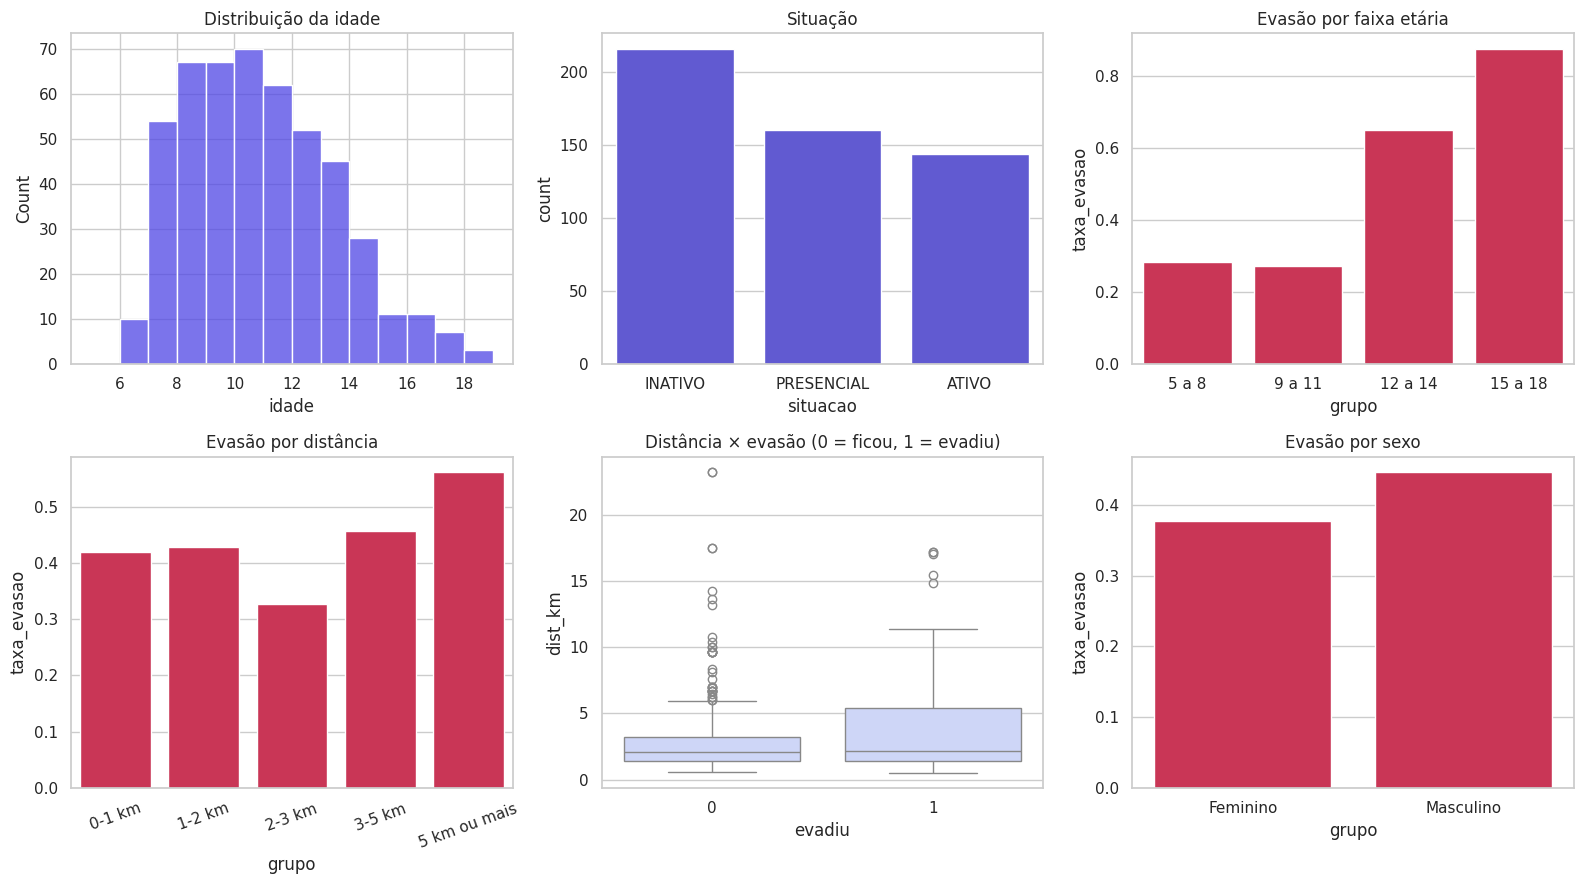

Qui-quadrado faixa de distância × evasão: chi2=12.50, gl=4, p=0.0140


In [6]:
def taxa(d, col, min_n=1):
    g = (d.groupby(col, observed=True)["evadiu"]
           .agg(inscritos="size", evadiram="sum").reset_index()
           .rename(columns={col: "grupo"}))
    g["taxa_evasao"] = g["evadiram"] / g["inscritos"]
    return g[g["inscritos"] >= min_n].reset_index(drop=True)

print("Taxa geral de evasão: %.1f%%  (%d de %d)" % (df.evadiu.mean()*100, df.evadiu.sum(), len(df)))
print("\nSituação:\n", df["situacao"].value_counts())
print("\nDistância (km):\n", df["dist_km"].describe().round(2))

fig, ax = plt.subplots(2, 3, figsize=(16, 9))
sns.histplot(df["idade"].dropna(), bins=range(5, 20), ax=ax[0, 0], color="#4f46e5"); ax[0, 0].set_title("Distribuição da idade")
sns.countplot(data=df, x="situacao", ax=ax[0, 1], color="#4f46e5"); ax[0, 1].set_title("Situação")
sns.barplot(data=taxa(df, "faixa_idade"), x="grupo", y="taxa_evasao", ax=ax[0, 2], color="#e11d48"); ax[0, 2].set_title("Evasão por faixa etária")
sns.barplot(data=taxa(df, "faixa_dist"), x="grupo", y="taxa_evasao", ax=ax[1, 0], color="#e11d48"); ax[1, 0].set_title("Evasão por distância")
ax[1, 0].tick_params(axis="x", rotation=20)
sns.boxplot(data=df, x="evadiu", y="dist_km", ax=ax[1, 1], color="#c7d2fe"); ax[1, 1].set_title("Distância × evasão (0 = ficou, 1 = evadiu)")
sns.barplot(data=taxa(df, "sexo"), x="grupo", y="taxa_evasao", ax=ax[1, 2], color="#e11d48"); ax[1, 2].set_title("Evasão por sexo")
plt.tight_layout(); plt.show()

# teste de hipótese: faixa de distância × evasão
tab = pd.crosstab(df["faixa_dist"], df["evadiu"])
chi2, p_qui2, gl, _ = chi2_contingency(tab)
print("Qui-quadrado faixa de distância × evasão: chi2=%.2f, gl=%d, p=%.4f" % (chi2, gl, p_qui2))

In [7]:
# dados faltantes — e atenção: faltar dado pode estar ligado ao alvo
falt = df[["idade_bruta", "dist_km", "tempo_min", "municipio", "bairro", "sexo"]].isna().mean().mul(100).round(1)
print("% de valores faltantes:\n", falt, "\n")

for nome, mascara in [("idade suspeita/ausente", df.idade_suspeita), ("sem endereço", df.sem_endereco)]:
    print("Evasão entre os registros com %s: %.1f%% (n=%d) | demais: %.1f%%" %
          (nome, df.loc[mascara, "evadiu"].mean()*100, mascara.sum(), df.loc[~mascara, "evadiu"].mean()*100))

% de valores faltantes:
 idade_bruta    3.5
dist_km        8.1
tempo_min      8.1
municipio      6.2
bairro         7.7
sexo           0.0
dtype: float64 

Evasão entre os registros com idade suspeita/ausente: 48.5% (n=33) | demais: 41.1%
Evasão entre os registros com sem endereço: 19.0% (n=42) | demais: 43.5%


## 4. Distância (Haversine) — opcional

A planilha já traz `DIST. KM` (distância **pelas ruas**). Se quiser também a distância em **linha reta**, preencha as coordenadas da escola
(Google Maps → clique com o botão direito no ponto → copiar latitude/longitude) e rode a célula.

In [8]:
ESCOLA_LAT, ESCOLA_LON = None, None   # ex.: -23.5000, -47.4500  (preencha)

def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0088
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dl = p2 - p1, np.radians(lon2) - np.radians(lon1)
    a = np.sin(dphi/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

if ESCOLA_LAT is not None:
    df["dist_reta_km"] = haversine(raw["LATITUDE"].values, raw["LONGITUDE"].values, ESCOLA_LAT, ESCOLA_LON)
    print(df[["dist_km", "dist_reta_km"]].corr().round(3))
else:
    print("Coordenadas da escola não informadas — etapa ignorada (dist_km da planilha será usada).")

Coordenadas da escola não informadas — etapa ignorada (dist_km da planilha será usada).


## 5. Modelagem supervisionada: Regressão Logística → Random Forest → XGBoost

Cuidados metodológicos:

* **`situacao` fica de fora** (é o próprio alvo — vazamento).
* **Imputação por mediana, sem indicadores de “faltou”**: dado faltante não é aleatório aqui (veja a seção 3: quem está sem endereço evadiu bem menos). Se o modelo enxergasse a ausência, estaria “prevendo” pela qualidade do cadastro, não pelo comportamento do aluno.
* **Validação cruzada estratificada repetida (5×3)**: com ~500 linhas, uma única divisão treino/teste é instável demais.
* Inclui um **baseline só com idade** para mostrar quanto a distância e as demais variáveis realmente acrescentam.

In [9]:
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

df["sexo_masc"] = (df["sexo"] == "Masculino").astype(int)
df["mun_votorantim"] = df["municipio"].map({"Sorocaba": 0, "Votorantim": 1})

FEATURES = ["idade", "sexo_masc", "dist_km", "tempo_min", "mun_votorantim"]
ROTULOS = {"idade": "Idade", "sexo_masc": "Sexo masculino", "dist_km": "Distância (km)",
           "tempo_min": "Tempo de carro (min)", "mun_votorantim": "Mora em Votorantim"}
X, y = df[FEATURES], df["evadiu"]

XGB_PARAMS = dict(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                  colsample_bytree=0.8, eval_metric="logloss", random_state=SEED)

def pipe(est, escalar=False):
    etapas = [("imp", SimpleImputer(strategy="median"))]
    if escalar: etapas.append(("sc", StandardScaler()))
    return Pipeline(etapas + [("clf", est)])

modelos = {
    "Baseline (só idade)": (pipe(LogisticRegression(max_iter=1000), True), ["idade"]),
    "Regressão Logística": (pipe(LogisticRegression(max_iter=1000), True), FEATURES),
    "Random Forest":       (pipe(RandomForestClassifier(n_estimators=400, min_samples_leaf=5, random_state=SEED, n_jobs=-1)), FEATURES),
    "XGBoost":             (pipe(XGBClassifier(**XGB_PARAMS)), FEATURES),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
linhas = []
for nome, (p, cols) in modelos.items():
    r = cross_validate(p, X[cols], y, cv=cv, n_jobs=1,
                       scoring={"auc": "roc_auc", "pr": "average_precision", "brier": "neg_brier_score"})
    linhas.append({"modelo": nome, "auc": r["test_auc"].mean(), "auc_dp": r["test_auc"].std(),
                   "pr_auc": r["test_pr"].mean(), "brier": -r["test_brier"].mean()})
resultados = pd.DataFrame(linhas).round(4)
print("Prevalência de evasão (referência do PR-AUC): %.3f" % y.mean())
resultados

Prevalência de evasão (referência do PR-AUC): 0.415


,modelo,auc,auc_dp,pr_auc,brier
0,Baseline (só idade),0.6968,0.0400,0.6431,0.2108
1,Regressão Logística,0.6944,0.0401,0.6415,0.2139
2,Random Forest,0.7185,0.0305,0.6690,0.2083
3,XGBoost,0.7258,0.0369,0.6746,0.2099


In [10]:
# melhor modelo (exclui o baseline) e probabilidades FORA DA AMOSTRA para cada aluno
melhor = resultados[resultados["modelo"] != "Baseline (só idade)"].sort_values("auc", ascending=False).iloc[0]["modelo"]
print("Melhor por AUC:", melhor)

pipe_melhor, cols_melhor = modelos[melhor]
df["risco_oof"] = cross_val_predict(pipe_melhor, X[cols_melhor], y,
                                    cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                                    method="predict_proba")[:, 1]
print("AUC fora da amostra: %.3f" % roc_auc_score(y, df["risco_oof"]))

# calibração: a evasão observada cresce com o risco previsto?
df["faixa_risco"] = pd.cut(df["risco_oof"], [0, 0.30, 0.60, 1.0], include_lowest=True,
                           labels=["Baixo (<30%)", "Médio (30–60%)", "Alto (≥60%)"])
risco_tab = taxa(df, "faixa_risco")
risco_tab

Melhor por AUC: XGBoost
AUC fora da amostra: 0.710


,grupo,inscritos,evadiram,taxa_evasao
0,Baixo (<30%),231,63,0.272727
1,Médio (30–60%),154,63,0.409091
2,Alto (≥60%),135,90,0.666667


## 6. Interpretação com SHAP

O SHAP mostra **o quanto cada variável empurra a previsão do modelo** para cima ou para baixo. Ele descreve o modelo, **não prova causa**:
distância, por exemplo, pode estar refletindo território, renda ou transporte.

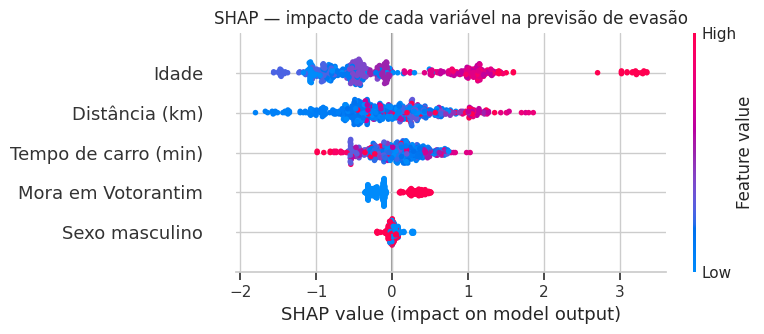

,variavel,importancia,sentido
0,Idade,0.812503,aumenta risco
1,Distância (km),0.513418,aumenta risco
2,Tempo de carro (min),0.297915,reduz risco
3,Mora em Votorantim,0.238500,aumenta risco
4,Sexo masculino,0.037628,reduz risco


In [11]:
imp = SimpleImputer(strategy="median").fit(X)
Xi = pd.DataFrame(imp.transform(X), columns=FEATURES)
xgb_final = XGBClassifier(**XGB_PARAMS).fit(Xi, y)

def sentido(v, ref):
    c = np.corrcoef(v, ref)[0, 1] if np.std(v) > 0 and np.std(ref) > 0 else 0
    return "aumenta risco" if c > 0.1 else "reduz risco" if c < -0.1 else "efeito misto"

try:
    import shap
    sv = shap.TreeExplainer(xgb_final).shap_values(Xi)
    shap.summary_plot(sv, Xi.rename(columns=ROTULOS), show=False)
    plt.title("SHAP — impacto de cada variável na previsão de evasão"); plt.tight_layout(); plt.show()
    importancias = np.abs(sv).mean(axis=0)
    sentidos = [sentido(Xi[c].values, sv[:, i]) for i, c in enumerate(FEATURES)]
    metodo_imp = "SHAP · média do |impacto|"
except ImportError:
    from sklearn.inspection import permutation_importance
    auc_scorer = lambda est, X_, y_: roc_auc_score(y_, est.predict_proba(X_)[:, 1])
    pi = permutation_importance(xgb_final, Xi, y, scoring=auc_scorer, n_repeats=20, random_state=SEED)
    importancias = pi.importances_mean
    sentidos = [sentido(Xi[c].values, y.values) for c in FEATURES]
    metodo_imp = "Importância por permutação (SHAP indisponível)"

shap_df = (pd.DataFrame({"variavel": [ROTULOS[c] for c in FEATURES], "importancia": importancias, "sentido": sentidos})
             .sort_values("importancia", ascending=False).reset_index(drop=True))
shap_df

## 7. Perfis com K-Means (não supervisionado)

In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cols_km = ["idade", "dist_km", "tempo_min"]
base = df.dropna(subset=cols_km).copy()
Z = StandardScaler().fit_transform(base[cols_km])

sil = {}
for k in range(2, 7):
    sil[k] = silhouette_score(Z, KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Z))
print("Silhouette por k:", {k: round(v, 3) for k, v in sil.items()})

K_ESCOLHIDO = max(sil, key=sil.get)    # troque por 3 ou 4 se preferir perfis mais interpretáveis
km = KMeans(n_clusters=K_ESCOLHIDO, n_init=10, random_state=SEED).fit(Z)
base["cluster"] = km.labels_

perfis = (base.groupby("cluster").agg(n=("evadiu", "size"), evadiram=("evadiu", "sum"),
                                      idade_media=("idade", "mean"), dist_media=("dist_km", "mean"),
                                      tempo_media=("tempo_min", "mean")).reset_index())
perfis["taxa_evasao"] = perfis["evadiram"] / perfis["n"]
perfis["perfil"] = ["Perfil " + chr(65 + i) for i in range(len(perfis))]
perfis["rotulo"] = ["idade média %.1f · %.1f km da escola" % (r.idade_media, r.dist_media) for r in perfis.itertuples()]
df["cluster"] = df.index.map(base["cluster"]).map(dict(zip(perfis["cluster"], perfis["perfil"])))
perfis.round(2)

Silhouette por k: {2: np.float64(0.523), 3: np.float64(0.418), 4: np.float64(0.448), 5: np.float64(0.431), 6: np.float64(0.393)}


,cluster,n,evadiram,idade_media,dist_media,tempo_media,taxa_evasao,perfil,rotulo
0,0,358,140,10.30,1.9,3.83,0.39,Perfil A,idade média 10.3 · 1.9 km da escola
1,1,97,53,11.34,8.4,11.76,0.55,Perfil B,idade média 11.3 · 8.4 km da escola


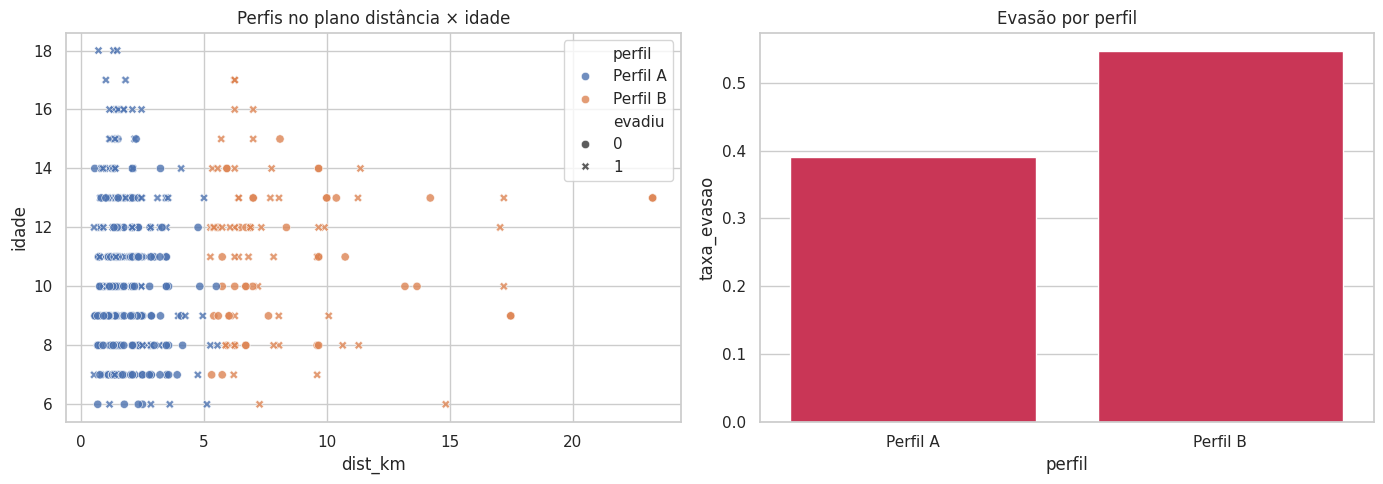

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=base.assign(perfil=base["cluster"].map(dict(zip(perfis["cluster"], perfis["perfil"])))),
                x="dist_km", y="idade", hue="perfil", style="evadiu", alpha=.8, ax=ax[0])
ax[0].set_title("Perfis no plano distância × idade")
sns.barplot(data=perfis, x="perfil", y="taxa_evasao", color="#e11d48", ax=ax[1]); ax[1].set_title("Evasão por perfil")
plt.tight_layout(); plt.show()

## 8. Dashboard web (HTML5 + Tailwind CSS + JavaScript)

O notebook monta um **JSON apenas com agregados** e o injeta num HTML autônomo. Não há dado individual no arquivo:
bairros com menos de 5 inscritos são suprimidos e o mapa usa só o centro do bairro.

In [14]:
def limpa(o):
    # converte tipos numpy e NaN em algo serializável em JSON
    if isinstance(o, dict):   return {k: limpa(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [limpa(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)): return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, (np.bool_,)): return bool(o)
    return o

def recs(d): return limpa(d.to_dict("records"))

# bairros (supressão de células pequenas: n >= 5)
g = df.groupby("bairro")
bairros = pd.DataFrame({
    "municipio": g["municipio"].agg(lambda s: s.mode().iat[0] if s.notna().any() else "—"),
    "inscritos": g.size(), "evadiram": g["evadiu"].sum(),
    "dist_media": g["dist_km"].mean(),
    "lat": g["lat"].mean().round(3), "lon": g["lon"].mean().round(3),
}).reset_index()
bairros["taxa_evasao"] = bairros["evadiram"] / bairros["inscritos"]
bairros = bairros[bairros["inscritos"] >= 5].sort_values("inscritos", ascending=False)

com_dist = df["dist_km"].notna()
n_susp = int(df["idade_suspeita"].sum())
ev_sem = df.loc[df.sem_endereco, "evadiu"].mean() * 100
ev_com = df.loc[~df.sem_endereco, "evadiu"].mean() * 100

payload = {
    "titulo": TITULO,
    "subtitulo": "%d inscritos · evasão = situação INATIVO" % len(df),
    "gerado_em": datetime.now().strftime("%d/%m/%Y %H:%M"),
    "kpis": {
        "total": len(df), "inativos": int(df["evadiu"].sum()),
        "taxa_evasao": df["evadiu"].mean(),
        "dist_mediana": df["dist_km"].median(),
        "dist_media_ficaram": df.loc[df.evadiu == 0, "dist_km"].mean(),
        "dist_media_evadiram": df.loc[df.evadiu == 1, "dist_km"].mean(),
        "n_com_distancia": int(com_dist.sum()), "p_qui2_dist": p_qui2,
    },
    "situacao": [{"grupo": k, "n": int(v)} for k, v in df["situacao"].value_counts().items()],
    "idade": recs(taxa(df, "faixa_idade")), "dist": recs(taxa(df, "faixa_dist")),
    "sexo": recs(taxa(df, "sexo")), "municipio": recs(taxa(df.dropna(subset=["municipio"]), "municipio")),
    "bairros": recs(bairros),
    "centro": {"lat": float(df["lat"].mean()), "lon": float(df["lon"].mean())},
    "modelos": recs(resultados), "melhor_modelo": melhor,
    "risco": recs(risco_tab),
    "shap": recs(shap_df), "shap_metodo": metodo_imp,
    "k": int(K_ESCOLHIDO), "silhouette": sil[K_ESCOLHIDO], "perfis": recs(perfis),
    "qualidade": [
        {"indicador": "Registros", "valor": len(df)},
        {"indicador": "Com distância calculada", "valor": "%d (%.0f%%)" % (com_dist.sum(), com_dist.mean()*100)},
        {"indicador": "Sem endereço", "valor": int(df["sem_endereco"].sum())},
        {"indicador": "Localização aproximada (centro de rua/bairro)", "valor": int(df["precisao_baixa"].sum())},
        {"indicador": "Idade suspeita ou ausente", "valor": n_susp},
        {"indicador": "Município não identificado", "valor": int(df["municipio"].isna().sum())},
        {"indicador": "Bairros exibidos (n ≥ 5)", "valor": len(bairros)},
    ],
    "dicionario": recs(dicionario),
    "notas": [
        "A planilha é uma foto do momento: não há datas de matrícula e saída. Inscritos mais velhos tiveram mais tempo para sair, então idade e evasão se misturam.",
        "Associação não é causa. Distância pode refletir território, renda, transporte ou rotina da família.",
        "Amostra pequena (~%d inscritos): olhe o desvio-padrão do AUC e use o modelo para priorizar a atenção da equipe, não para decidir sobre uma criança." % len(df),
        "Dado ausente não é aleatório: entre os %d inscritos sem endereço a evasão é %.0f%% (demais: %.0f%%). Eles entram nos modelos com a distância mediana e sem indicador de ausência." % (df["sem_endereco"].sum(), ev_sem, ev_com),
        "Faixas de risco: confira no gráfico de calibração se a evasão observada realmente sobe de Baixo para Alto antes de usar.",
    ],
}

HTML_TEMPLATE = r'''<!DOCTYPE html>
<html lang="pt-BR">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>__TITULO__</title>
<script src="https://cdn.tailwindcss.com/3.4.17"></script>
<link rel="stylesheet" href="https://cdnjs.cloudflare.com/ajax/libs/leaflet/1.9.4/leaflet.css">
<script src="https://cdnjs.cloudflare.com/ajax/libs/Chart.js/4.4.1/chart.umd.min.js"></script>
<script src="https://cdnjs.cloudflare.com/ajax/libs/leaflet/1.9.4/leaflet.js"></script>
<style>
  .tab-btn[aria-selected="true"]{border-color:#4f46e5;color:#4f46e5;font-weight:600}
  #map{height:460px;border-radius:.75rem;z-index:0}
  th.sortable{cursor:pointer;user-select:none}
  .chart-box{position:relative;height:280px}
</style>
</head>
<body class="bg-slate-50 text-slate-800">

<header class="bg-white border-b">
  <div class="max-w-7xl mx-auto px-4 py-5 flex flex-wrap items-center justify-between gap-2">
    <div>
      <h1 class="text-xl font-semibold">__TITULO__</h1>
      <p class="text-sm text-slate-500" id="sub"></p>
    </div>
    <span class="text-xs bg-amber-50 text-amber-800 border border-amber-200 rounded px-2 py-1">
      Dados agregados e anonimizados · sem nomes, CPF ou endereços
    </span>
  </div>
  <nav class="max-w-7xl mx-auto px-4 flex gap-6 text-sm overflow-x-auto" role="tablist" id="tabs"></nav>
</header>

<main class="max-w-7xl mx-auto px-4 py-6">

  <!-- VISÃO GERAL -->
  <section id="tab-geral" class="tab space-y-6">
    <div id="kpis" class="grid grid-cols-2 md:grid-cols-3 lg:grid-cols-6 gap-4"></div>
    <div class="grid md:grid-cols-2 gap-6">
      <div class="bg-white rounded-xl border shadow-sm p-4"><h2 class="font-medium mb-2">Situação dos inscritos</h2><div class="chart-box"><canvas id="cSituacao"></canvas></div></div>
      <div class="bg-white rounded-xl border shadow-sm p-4"><h2 class="font-medium mb-2">Taxa de evasão por faixa etária</h2><div class="chart-box"><canvas id="cIdade"></canvas></div></div>
      <div class="bg-white rounded-xl border shadow-sm p-4"><h2 class="font-medium mb-1">Taxa de evasão por distância até a escola</h2><p id="pDist" class="text-xs text-slate-500 mb-2"></p><div class="chart-box"><canvas id="cDist"></canvas></div></div>
      <div class="grid grid-rows-2 gap-6">
        <div class="bg-white rounded-xl border shadow-sm p-4"><h2 class="font-medium mb-2">Por sexo</h2><div style="position:relative;height:100px"><canvas id="cSexo"></canvas></div></div>
        <div class="bg-white rounded-xl border shadow-sm p-4"><h2 class="font-medium mb-2">Por município</h2><div style="position:relative;height:100px"><canvas id="cMun"></canvas></div></div>
      </div>
    </div>
  </section>

  <!-- TERRITÓRIO -->
  <section id="tab-territorio" class="tab hidden space-y-6">
    <div class="flex flex-wrap items-center gap-3">
      <label for="selMun" class="text-sm font-medium">Município</label>
      <select id="selMun" class="border rounded-lg px-3 py-1.5 text-sm bg-white"></select>
      <span class="text-xs text-slate-500">Bolhas = centro de cada bairro com 5+ inscritos (nunca endereços individuais). Tamanho = nº de inscritos · cor = taxa de evasão.</span>
    </div>
    <div id="map"></div>
    <div class="bg-white rounded-xl border shadow-sm overflow-x-auto">
      <table class="w-full text-sm">
        <thead class="bg-slate-100 text-left"><tr id="thBairros"></tr></thead>
        <tbody id="tbBairros"></tbody>
      </table>
    </div>
  </section>

  <!-- MODELO -->
  <section id="tab-modelo" class="tab hidden space-y-6">
    <div class="grid md:grid-cols-2 gap-6">
      <div class="bg-white rounded-xl border shadow-sm p-4">
        <h2 class="font-medium mb-1">Comparação de modelos (validação cruzada 5×3)</h2>
        <p class="text-xs text-slate-500 mb-3">AUC-ROC: 0,5 = acaso · 1,0 = perfeito.</p>
        <table class="w-full text-sm"><thead class="text-left text-slate-500"><tr><th class="py-1">Modelo</th><th>AUC</th><th>PR-AUC</th><th>Brier</th></tr></thead><tbody id="tbModelos"></tbody></table>
      </div>
      <div class="bg-white rounded-xl border shadow-sm p-4">
        <h2 class="font-medium mb-1">Calibração: evasão observada por faixa de risco previsto</h2>
        <p class="text-xs text-slate-500 mb-2">Probabilidades fora da amostra. Se o modelo é bom, a barra cresce de Baixo para Alto.</p>
        <div class="chart-box"><canvas id="cRisco"></canvas></div>
      </div>
    </div>
    <div class="bg-white rounded-xl border shadow-sm p-4">
      <h2 class="font-medium mb-1" id="hShap">Importância das variáveis</h2>
      <p class="text-xs text-slate-500 mb-2">Vermelho: valores maiores da variável aumentam o risco previsto · Verde: reduzem · Cinza: efeito misto.</p>
      <div style="position:relative;height:260px"><canvas id="cShap"></canvas></div>
    </div>
    <div class="bg-amber-50 border border-amber-200 rounded-xl p-4 text-sm">
      <h2 class="font-medium mb-2">Como interpretar</h2>
      <ul id="notas" class="list-disc pl-5 space-y-1 text-amber-900"></ul>
    </div>
  </section>

  <!-- PERFIS -->
  <section id="tab-perfis" class="tab hidden space-y-6">
    <div class="grid md:grid-cols-2 gap-6">
      <div class="bg-white rounded-xl border shadow-sm p-4 overflow-x-auto">
        <h2 class="font-medium mb-1">Perfis encontrados pelo K-Means</h2>
        <p id="pPerfis" class="text-xs text-slate-500 mb-3"></p>
        <table class="w-full text-sm"><thead class="text-left text-slate-500"><tr><th class="py-1">Perfil</th><th>Inscritos</th><th>Idade média</th><th>Dist. média (km)</th><th>Evasão</th></tr></thead><tbody id="tbPerfis"></tbody></table>
      </div>
      <div class="bg-white rounded-xl border shadow-sm p-4"><h2 class="font-medium mb-2">Taxa de evasão por perfil</h2><div class="chart-box"><canvas id="cPerfis"></canvas></div></div>
    </div>
  </section>

  <!-- DADOS -->
  <section id="tab-dados" class="tab hidden space-y-6">
    <div class="bg-white rounded-xl border shadow-sm p-4">
      <h2 class="font-medium mb-3">Qualidade dos dados</h2>
      <dl id="qualidade" class="grid sm:grid-cols-2 lg:grid-cols-3 gap-x-8 gap-y-2 text-sm"></dl>
    </div>
    <div class="bg-white rounded-xl border shadow-sm p-4 overflow-x-auto">
      <h2 class="font-medium mb-3">Dicionário de variáveis</h2>
      <table class="w-full text-sm"><thead class="text-left text-slate-500"><tr><th class="py-1">Variável</th><th>Descrição</th><th>Tipo</th><th>Papel</th></tr></thead><tbody id="tbDic"></tbody></table>
    </div>
  </section>

</main>
<footer class="text-center text-xs text-slate-400 py-6" id="foot"></footer>

<script>
const D = __DATA__;
const $ = s => document.querySelector(s);
const pct = v => v == null ? '–' : (v * 100).toFixed(1).replace('.', ',') + '%';
const num = (v, d = 1) => v == null ? '–' : Number(v).toFixed(d).replace('.', ',');
const C = { primary: '#4f46e5', danger: '#e11d48', ok: '#059669', muted: '#94a3b8' };
Chart.defaults.font.family = 'ui-sans-serif, system-ui, sans-serif';

$('#sub').textContent = D.subtitulo;
$('#foot').textContent = 'Gerado em ' + D.gerado_em + ' · Python (Pandas, scikit-learn, XGBoost, SHAP) no Google Colab';

/* ---------- abas ---------- */
const TABS = [['geral', 'Visão geral'], ['territorio', 'Território'], ['modelo', 'Modelo preditivo'], ['perfis', 'Perfis (K-Means)'], ['dados', 'Qualidade e dicionário']];
const nav = $('#tabs');
TABS.forEach(([id, label], i) => {
  const b = document.createElement('button');
  b.className = 'tab-btn py-3 border-b-2 border-transparent hover:text-indigo-600 whitespace-nowrap';
  b.textContent = label; b.dataset.id = id;
  b.setAttribute('role', 'tab'); b.setAttribute('aria-selected', i === 0);
  b.onclick = () => show(id);
  nav.appendChild(b);
});
var map = null;
function show(id) {
  document.querySelectorAll('.tab').forEach(s => s.classList.toggle('hidden', s.id !== 'tab-' + id));
  nav.querySelectorAll('button').forEach(b => b.setAttribute('aria-selected', b.dataset.id === id));
  if (id === 'territorio' && map) setTimeout(() => map.invalidateSize(), 50);
}

/* ---------- KPIs ---------- */
const K = D.kpis;
[
  ['Inscritos', K.total],
  ['Inativos (evadiram)', K.inativos],
  ['Taxa de evasão', pct(K.taxa_evasao)],
  ['Distância mediana (km)', num(K.dist_mediana)],
  ['Dist. média · permanecem', num(K.dist_media_ficaram)],
  ['Dist. média · evadiram', num(K.dist_media_evadiram)]
].forEach(([t, v]) => {
  $('#kpis').insertAdjacentHTML('beforeend',
    `<div class="bg-white rounded-xl border shadow-sm p-4"><p class="text-xs text-slate-500">${t}</p><p class="text-2xl font-semibold mt-1">${v}</p></div>`);
});

/* ---------- gráficos de taxa ---------- */
function rateChart(id, rows, horizontal = false) {
  new Chart($(id), {
    type: 'bar',
    data: { labels: rows.map(r => r.grupo), datasets: [{ data: rows.map(r => r.taxa_evasao * 100), backgroundColor: C.primary, borderRadius: 6 }] },
    options: {
      indexAxis: horizontal ? 'y' : 'x', maintainAspectRatio: false,
      plugins: { legend: { display: false }, tooltip: { callbacks: {
        label: c => 'Taxa de evasão: ' + c.parsed[horizontal ? 'x' : 'y'].toFixed(1) + '%',
        afterLabel: c => { const r = rows[c.dataIndex]; return r.evadiram + ' de ' + r.inscritos + ' inscritos'; } } } },
      scales: { [horizontal ? 'x' : 'y']: { beginAtZero: true, max: 100, ticks: { callback: v => v + '%' } } }
    }
  });
}
new Chart($('#cSituacao'), {
  type: 'doughnut',
  data: { labels: D.situacao.map(r => r.grupo), datasets: [{ data: D.situacao.map(r => r.n), backgroundColor: [C.ok, C.primary, C.danger] }] },
  options: { maintainAspectRatio: false, plugins: { legend: { position: 'right' } } }
});
rateChart('#cIdade', D.idade);
rateChart('#cDist', D.dist);
rateChart('#cSexo', D.sexo, true);
rateChart('#cMun', D.municipio, true);
$('#pDist').textContent = D.kpis.p_qui2_dist == null ? '' :
  'Teste qui-quadrado (faixa × evasão): p = ' + D.kpis.p_qui2_dist.toFixed(3).replace('.', ',') +
  ' · ' + K.n_com_distancia + ' inscritos com distância calculada.';

/* ---------- território ---------- */
const B = D.bairros;
const sel = $('#selMun');
['Todos', ...new Set(B.map(b => b.municipio))].forEach(m => sel.add(new Option(m, m)));
let sortKey = 'inscritos', sortDir = -1;
const COLS = [['bairro', 'Bairro'], ['municipio', 'Município'], ['inscritos', 'Inscritos'], ['evadiram', 'Evadiram'], ['taxa_evasao', 'Taxa de evasão'], ['dist_media', 'Dist. média (km)']];
COLS.forEach(([k, l]) => {
  const th = document.createElement('th'); th.className = 'sortable px-3 py-2'; th.textContent = l;
  th.onclick = () => { sortDir = (sortKey === k) ? -sortDir : -1; sortKey = k; render(); };
  $('#thBairros').appendChild(th);
});
const colorOf = t => `hsl(${Math.round(120 * (1 - Math.min(1, t / 0.9)))},65%,45%)`;
map = L.map('map').setView([D.centro.lat, D.centro.lon], 12);
L.tileLayer('https://{s}.tile.openstreetmap.org/{z}/{x}/{y}.png', { attribution: '© OpenStreetMap' }).addTo(map);
const layer = L.layerGroup().addTo(map);
function render() {
  const rows = B.filter(b => sel.value === 'Todos' || b.municipio === sel.value)
    .sort((a, b) => ((a[sortKey] ?? -1) > (b[sortKey] ?? -1) ? 1 : -1) * sortDir);
  $('#tbBairros').innerHTML = rows.map(b => `<tr class="border-t"><td class="px-3 py-2">${b.bairro}</td><td class="px-3">${b.municipio}</td><td class="px-3">${b.inscritos}</td><td class="px-3">${b.evadiram}</td><td class="px-3">${pct(b.taxa_evasao)}</td><td class="px-3">${num(b.dist_media)}</td></tr>`).join('');
  layer.clearLayers();
  rows.filter(b => b.lat != null).forEach(b => L.circleMarker([b.lat, b.lon], {
    radius: 5 + Math.sqrt(b.inscritos) * 1.8, color: '#334155', weight: 1,
    fillColor: colorOf(b.taxa_evasao), fillOpacity: .7
  }).bindPopup(`<b>${b.bairro}</b><br>${b.inscritos} inscritos · ${b.evadiram} evadiram<br>Taxa: ${pct(b.taxa_evasao)}`).addTo(layer));
}
sel.onchange = render; render();

/* ---------- modelo ---------- */
$('#tbModelos').innerHTML = D.modelos.map(m =>
  `<tr class="border-t ${m.modelo === D.melhor_modelo ? 'bg-indigo-50 font-medium' : ''}"><td class="py-1.5">${m.modelo}</td><td>${num(m.auc, 3)} ± ${num(m.auc_dp, 3)}</td><td>${num(m.pr_auc, 3)}</td><td>${num(m.brier, 3)}</td></tr>`).join('');
new Chart($('#cRisco'), {
  type: 'bar',
  data: { labels: D.risco.map(r => r.grupo), datasets: [{ data: D.risco.map(r => r.taxa_evasao * 100), backgroundColor: [C.ok, '#f59e0b', C.danger], borderRadius: 6 }] },
  options: { maintainAspectRatio: false, plugins: { legend: { display: false }, tooltip: { callbacks: {
    label: c => 'Evasão observada: ' + c.parsed.y.toFixed(1) + '%',
    afterLabel: c => D.risco[c.dataIndex].inscritos + ' inscritos' } } },
    scales: { y: { beginAtZero: true, max: 100, ticks: { callback: v => v + '%' } } } }
});
$('#hShap').textContent = 'Importância das variáveis (' + D.shap_metodo + ')';
new Chart($('#cShap'), {
  type: 'bar',
  data: { labels: D.shap.map(s => s.variavel), datasets: [{ data: D.shap.map(s => s.importancia),
    backgroundColor: D.shap.map(s => s.sentido === 'aumenta risco' ? C.danger : s.sentido === 'reduz risco' ? C.ok : C.muted), borderRadius: 6 }] },
  options: { indexAxis: 'y', maintainAspectRatio: false, plugins: { legend: { display: false }, tooltip: { callbacks: { afterLabel: c => D.shap[c.dataIndex].sentido } } } }
});
$('#notas').innerHTML = D.notas.map(n => `<li>${n}</li>`).join('');

/* ---------- perfis ---------- */
$('#pPerfis').textContent = 'k = ' + D.k + ' perfis (silhouette = ' + num(D.silhouette, 2) + '), usando idade, distância e tempo de carro padronizados.';
$('#tbPerfis').innerHTML = D.perfis.map(p =>
  `<tr class="border-t"><td class="py-1.5"><b>${p.perfil}</b><br><span class="text-xs text-slate-500">${p.rotulo}</span></td><td>${p.n}</td><td>${num(p.idade_media)}</td><td>${num(p.dist_media)}</td><td>${pct(p.taxa_evasao)}</td></tr>`).join('');
rateChart('#cPerfis', D.perfis.map(p => ({ grupo: p.perfil, inscritos: p.n, evadiram: p.evadiram, taxa_evasao: p.taxa_evasao })));

/* ---------- dados ---------- */
$('#qualidade').innerHTML = D.qualidade.map(q => `<div class="flex justify-between border-b py-1"><dt class="text-slate-500">${q.indicador}</dt><dd class="font-medium">${q.valor}</dd></div>`).join('');
$('#tbDic').innerHTML = D.dicionario.map(d => `<tr class="border-t align-top"><td class="py-1.5 font-mono text-xs">${d.variavel}</td><td>${d.descricao}</td><td>${d.tipo}</td><td>${d.papel}</td></tr>`).join('');
</script>
</body>
</html>
'''

html = (HTML_TEMPLATE.replace("__TITULO__", TITULO)
                     .replace("__DATA__", json.dumps(limpa(payload), ensure_ascii=False)))
with open("dashboard_evasao.html", "w", encoding="utf-8") as f:
    f.write(html)
print("dashboard_evasao.html gerado: %.0f KB" % (len(html)/1024))

dashboard_evasao.html gerado: 24 KB


In [15]:
# pré-visualização dentro do Colab (para o mapa e as fontes, abra também o arquivo baixado no navegador)
from IPython.display import HTML, display
import html as _h
display(HTML('<iframe style="width:100%;height:900px;border:1px solid #e2e8f0;border-radius:8px" srcdoc="' + _h.escape(html, quote=True) + '"></iframe>'))

## 9. Exportações: Power BI, slides e download

Arquivos **só com agregados** (sem nenhum dado individual), prontos para Power BI e para os slides.

In [16]:
with pd.ExcelWriter("agregados_powerbi.xlsx") as w:
    taxa(df, "faixa_idade").to_excel(w, sheet_name="evasao_idade", index=False)
    taxa(df, "faixa_dist").to_excel(w, sheet_name="evasao_distancia", index=False)
    taxa(df, "sexo").to_excel(w, sheet_name="evasao_sexo", index=False)
    taxa(df.dropna(subset=["municipio"]), "municipio").to_excel(w, sheet_name="evasao_municipio", index=False)
    bairros.to_excel(w, sheet_name="evasao_bairro", index=False)
    resultados.to_excel(w, sheet_name="modelos", index=False)
    shap_df.to_excel(w, sheet_name="importancia_variaveis", index=False)
    perfis.drop(columns=["cluster"]).to_excel(w, sheet_name="perfis_kmeans", index=False)
    risco_tab.to_excel(w, sheet_name="calibracao_risco", index=False)
    dicionario.to_excel(w, sheet_name="dicionario", index=False)
print("agregados_powerbi.xlsx gerado")

if IN_COLAB:
    files.download("dashboard_evasao.html")
    files.download("agregados_powerbi.xlsx")

agregados_powerbi.xlsx gerado


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Publicar o dashboard
* **Mais simples:** enviar `dashboard_evasao.html` por e-mail ou abrir direto no navegador.
* **Link interno:** GitHub Pages, Netlify Drop ou Google Sites (incorporar HTML) — *só publique em local de acesso restrito*, mesmo sendo dados agregados.
* **Atualização:** troque a planilha, rode *Executar tudo* e substitua o HTML.